<a href="https://colab.research.google.com/github/abdul5675/CSA4703-DEEP-LEARNING/blob/main/DL_IMPLEMENTATION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

path = '/content/drive/MyDrive/'

print(os.listdir(path))

['Colab Notebooks', 'razak gurupadigam.pdf', 'oct 18 pdf.pdf', 'Oct 28 pdf.pdf', 'Nov9 pdf.pdf', 'Nov 19 pdf.pdf', 'DocScanner 11 Nov 2025 3-23\u202fpm.pdf', 'Nov 24  pdf.pdf', 'GP dec 16.pdf', 'Gp 30.pdf', 'Gp 3.pdf', 'pdf.pdf', 'Gp jan 13.pdf', 'DocScanner Feb 3, 2026 11-14 AM.pdf', 'Classroom', 'gp 23 (1).pdf', 'gp 23.pdf', 'gp 3.pdf', 'gp 16 march.pdf', 'DocScanner Apr 1, 2026 12-47 PM.pdf', '4 gp.pdf', 'April 11.pdf', '11 may.pdf', 'DocScannerMay14,20268-43AM.pdf', '17 may.pdf', 'gp 8.pdf', 'gp 22.pdf', 'Gp 29.pdf', 'July 27 gp.pdf', 'file_00000000bd4481f5aead985cf8811fe5.png', 'gp 10.pdf', 'IMG_20260814_093225.jpg', 'AUG 17 GP PDF.pptx', 'Copy of CO3-AT1 CV', 'CO3-AT1-AT2 & AT3 QUESTION (1).gdoc', 'CO3-AT1-AT2 & AT3 QUESTION.gdoc', 'Copy of CO4_AT1_CV.ipynb', 'CO4-AT1-AT2 & AT3 QUESTION (1).gdoc', 'CO4-AT1-AT2 & AT3 QUESTION.gdoc', '17872380874822525095593142558462.jpg', '17872381182136287937396977948519.jpg', '17872385116022407209282734886783.jpg', '17872385490492986443863929236

In [ ]:
import os

path = '/content/drive/MyDrive/DATASET '

print("Dataset contents:")
print(os.listdir(path))

Dataset contents:
['archive (1)']


In [ ]:
import os

dataset_path = '/content/drive/MyDrive/DATASET /archive (1)'

print(os.listdir(dataset_path))

['Computed Tomography (CT) of the Brain']


In [ ]:
import os

dataset_path = '/content/drive/MyDrive/DATASET /archive (1)/Computed Tomography (CT) of the Brain'

for folder in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder)

    if os.path.isdir(folder_path):
        print(folder, ":", os.listdir(folder_path))

dataset : ['train', 'test']


In [ ]:
import os

for folder in ['train', 'test']:
    # Added 'dataset' folder to the path structure
    folder_path = os.path.join(dataset_path, 'dataset', folder)

    print("\n", folder.upper())

    for class_name in os.listdir(folder_path):
        class_path = os.path.join(folder_path, class_name)

        if os.path.isdir(class_path):
            print(class_name, ":", len(os.listdir(class_path)), "files")


 TRAIN
tumor : 841 files
cancer : 296 files
aneurysm : 842 files

 TEST
tumor : 48 files
cancer : 48 files
aneurysm : 48 files


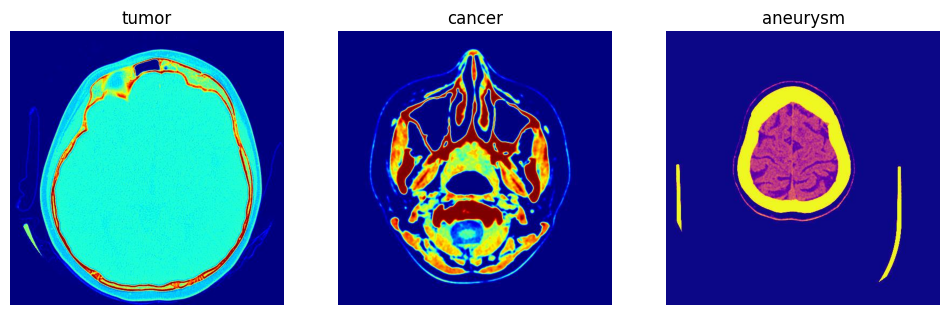

In [ ]:
import matplotlib.pyplot as plt
import os
from PIL import Image
import random

classes = ['tumor', 'cancer', 'aneurysm']

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes):
    # Added 'dataset' to match the actual folder structure
    folder = os.path.join(dataset_path, 'dataset', 'train', class_name)

    images = [f for f in os.listdir(folder)
              if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    image_name = random.choice(images)
    image = Image.open(os.path.join(folder, image_name))

    plt.subplot(1, 3, i+1)
    plt.imshow(image, cmap='gray')
    plt.title(class_name)
    plt.axis('off')

plt.show()

In [ ]:
from PIL import Image
import os
from collections import Counter

classes = ['tumor', 'cancer', 'aneurysm']

for class_name in classes:
    # Added 'dataset' folder to correctly construct the path structure
    folder = os.path.join(dataset_path, 'dataset', 'train', class_name)

    dimensions = Counter()
    modes = Counter()
    formats = Counter()

    for file in os.listdir(folder):
        try:
            img = Image.open(os.path.join(folder, file))

            dimensions[img.size] += 1
            modes[img.mode] += 1
            formats[img.format] += 1

        except:
            continue

    print("\nClass:", class_name)
    print("Image dimensions:", dimensions.most_common(5))
    print("Image modes:", modes)
    print("Image formats:", formats)


Class: tumor
Image dimensions: [((512, 512), 841)]
Image modes: Counter({'RGB': 841})
Image formats: Counter({'JPEG': 841})

Class: cancer
Image dimensions: [((512, 512), 296)]
Image modes: Counter({'RGB': 296})
Image formats: Counter({'JPEG': 296})

Class: aneurysm
Image dimensions: [((512, 512), 842)]
Image modes: Counter({'RGB': 842})
Image formats: Counter({'JPEG': 842})


In [ ]:
import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Corrected directories by adding the 'dataset' subfolder
train_dir = os.path.join(dataset_path, 'dataset', 'train')
test_dir = os.path.join(dataset_path, 'dataset', 'test')

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    validation_split=0.2,
    subset='training',
    seed=SEED
)

# Save class names before prefetching transforms the dataset
class_names = train_ds.class_names

# Load validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    validation_split=0.2,
    subset='validation',
    seed=SEED
)

# Load independent testing dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    class_names=class_names,
    shuffle=False
)

# Improve loading performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Classes:", class_names)
print("Preprocessing completed!")

Found 1979 files belonging to 3 classes.
Using 1584 files for training.
Found 1979 files belonging to 3 classes.
Using 395 files for validation.
Found 144 files belonging to 3 classes.
Classes: ['aneurysm', 'cancer', 'tumor']
Preprocessing completed!


In [ ]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Minimum pixel:", tf.reduce_min(images).numpy())
    print("Maximum pixel:", tf.reduce_max(images).numpy())

Image shape: (32, 224, 224, 3)
Label shape: (32,)
Minimum pixel: 0.0
Maximum pixel: 255.0


In [ ]:
import tensorflow as tf

print("GPU Available:", tf.config.list_physical_devices('GPU'))

GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Data augmentation
augmentation = models.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.1)
])

# CNN architecture
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(3, activation='softmax')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Ensure preceding cells have been executed so that train_ds exists
labels = np.concatenate([
    y.numpy() for x, y in train_ds
])

weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(labels),
    y=labels
)

class_weights = dict(enumerate(weights))

# Referencing class_names variable saved during preprocessing
print("Class names:", class_names)
print("Class weights:", class_weights)

Class names: ['aneurysm', 'cancer', 'tumor']
Class weights: {0: np.float64(0.7685589519650655), 1: np.float64(2.2), 2: np.float64(0.8036529680365296)}


In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")


CNN model compiled successfully!


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        '/content/drive/MyDrive/brain_ct_cnn_best.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        patience=2,
        factor=0.5
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 183ms/step - accuracy: 0.9078 - loss: 0.3086 - val_accuracy: 0.9899 - val_loss: 0.0093 - learning_rate: 0.0010
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 113ms/step - accuracy: 0.9848 - loss: 0.0567 - val_accuracy: 0.9924 - val_loss: 0.0186 - learning_rate: 0.0010
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 307ms/step - accuracy: 0.9880 - loss: 0.0367 - val_accuracy: 1.0000 - val_loss: 0.0056 - learning_rate: 0.0010
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 119ms/step - accuracy: 0.9956 - loss: 0.0091 - val_accuracy: 1.0000 - val_loss: 5.1975e-04 - learning_rate: 0.0010
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 192ms/step - accuracy: 0.9956 - loss: 0.0193 - val_accuracy: 0.9899 - val_loss: 0.0448 - learning_rate: 0.0010
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 137ms/step - accuracy: 0.9912 - loss: 0.0287 - val_accuracy: 1.0000 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 135ms/step - accuracy: 0.9987 - loss: 0.

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

print("Folders in MyDrive:")
for folder in os.listdir('/content/drive/MyDrive'):
    print(folder)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folders in MyDrive:
Colab Notebooks
razak gurupadigam.pdf
oct 18 pdf.pdf
Oct 28 pdf.pdf
Nov9 pdf.pdf
Nov 19 pdf.pdf
DocScanner 11 Nov 2025 3-23 pm.pdf
Nov 24  pdf.pdf
GP dec 16.pdf
Gp 30.pdf
Gp 3.pdf
pdf.pdf
Gp jan 13.pdf
DocScanner Feb 3, 2026 11-14 AM.pdf
Classroom
gp 23 (1).pdf
gp 23.pdf
gp 3.pdf
gp 16 march.pdf
DocScanner Apr 1, 2026 12-47 PM.pdf
4 gp.pdf
April 11.pdf
11 may.pdf
DocScannerMay14,20268-43AM.pdf
17 may.pdf
gp 8.pdf
gp 22.pdf
Gp 29.pdf
July 27 gp.pdf
file_00000000bd4481f5aead985cf8811fe5.png
gp 10.pdf
IMG_20260814_093225.jpg
AUG 17 GP PDF.pptx
Copy of CO3-AT1 CV
CO3-AT1-AT2 & AT3 QUESTION (1).gdoc
CO3-AT1-AT2 & AT3 QUESTION.gdoc
Copy of CO4_AT1_CV.ipynb
CO4-AT1-AT2 & AT3 QUESTION (1).gdoc
CO4-AT1-AT2 & AT3 QUESTION.gdoc
17872380874822525095593142558462.jpg
17872381182136287937396977948519.jpg
17872385116022407209282734886783.jpg
1787238549049

In [ ]:

import os

dataset_root = '/content/drive/MyDrive/DATASET '

for root, dirs, files in os.walk(dataset_root):
    level = root.replace(dataset_root, '').count(os.sep)
    if level <= 5:
        print("  " * level + os.path.basename(root) + "/")


DATASET /
  archive (1)/
    Computed Tomography (CT) of the Brain/
      dataset/
        train/
          tumor/
          cancer/
          aneurysm/
        test/
          tumor/
          cancer/
          aneurysm/


In [ ]:

import tensorflow as tf

dataset_path = '/content/drive/MyDrive/DATASET /archive (1)/Computed Tomography (CT) of the Brain/dataset'

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path + '/test',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    class_names=['aneurysm', 'cancer', 'tumor'],
    shuffle=False
)

print("Test dataset loaded successfully!")


Found 144 files belonging to 3 classes.
Test dataset loaded successfully!


In [ ]:

model = tf.keras.models.load_model(
    '/content/drive/MyDrive/brain_ct_cnn_best.keras'
)

print("CNN model loaded successfully!")


CNN model loaded successfully!


In [ ]:

test_loss, test_accuracy = model.evaluate(test_ds)

print("Final Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Final Test Loss:", round(test_loss, 4))


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 1.0000 - loss: 0.0000e+00
Final Test Accuracy: 100.0 %
Final Test Loss: 0.0


4/5 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
Classification Report:
              precision    recall  f1-score   support

    aneurysm       1.00      1.00      1.00        48
      cancer       1.00      1.00      1.00        48
       tumor       1.00      1.00      1.00        48

    accuracy                           1.00       144
   macro avg       1.00      1.00      1.00       144
weighted avg       1.00      1.00      1.00       144



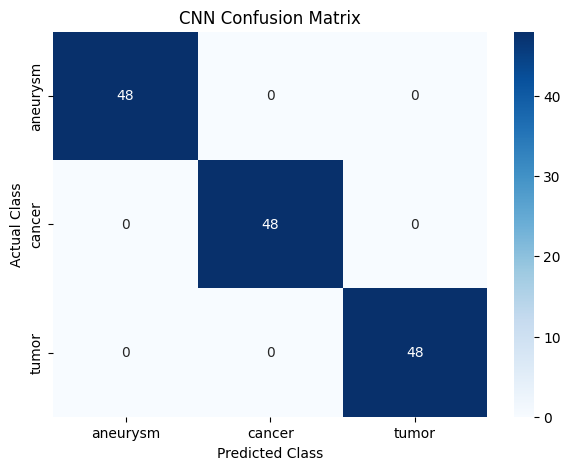

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

y_true = np.concatenate([y.numpy() for x, y in test_ds])

predictions = model.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

class_names = ['aneurysm', 'cancer', 'tumor']

print("Classification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=class_names
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN Confusion Matrix")
plt.show()


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Preserve the previously trained CNN
cnn_model = model

# Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze pretrained layers
base_model.trainable = False

# Build MobileNetV2 model
mobilenet_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.08),
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(3, activation='softmax')
])

# Compile model
mobilenet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("MobileNetV2 model compiled successfully!")
mobilenet_model.summary()


MobileNetV2 model compiled successfully!


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation_2               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

class_names = ['aneurysm', 'cancer', 'tumor']

test_path = dataset_path + '/test'

# Select one image randomly
actual_class = random.choice(class_names)
class_folder = os.path.join(test_path, actual_class)

image_file = random.choice(os.listdir(class_folder))
image_path = os.path.join(class_folder, image_file)

print("Selected image:", image_file)
print("Actual class:", actual_class)


Selected image: 2_12.jpg
Actual class: tumor


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step


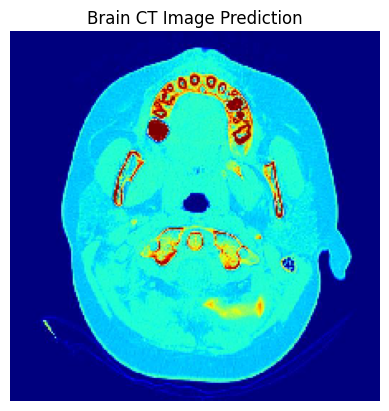

Actual Class: tumor
Predicted Class: tumor
Prediction Confidence: 100.0 %
Result: CORRECT PREDICTION


In [ ]:

# Load and preprocess image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict using trained CNN
prediction = model.predict(img_array)

predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

# Display image
plt.imshow(img)
plt.axis('off')
plt.title("Brain CT Image Prediction")
plt.show()

# Display results
print("Actual Class:", actual_class)
print("Predicted Class:", predicted_class)
print("Prediction Confidence:", round(confidence, 2), "%")

if actual_class == predicted_class:
    print("Result: CORRECT PREDICTION")
else:
    print("Result: INCORRECT PREDICTION")


Saving Monochrome Axial Brain CT Scan.png to Monochrome Axial Brain CT Scan.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


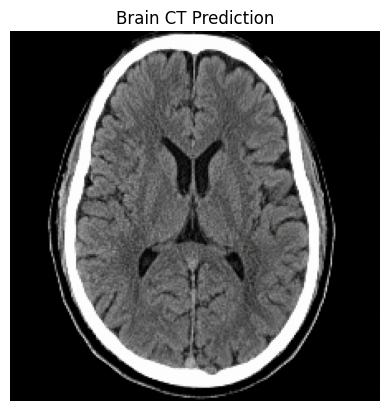

Predicted Class: tumor
Confidence: 99.15 %


In [ ]:

from google.colab import files
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Upload image from computer
uploaded = files.upload()

# Get uploaded image path
image_path = list(uploaded.keys())[0]

# Load and resize image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

# Convert image into array
img_array = tf.keras.utils.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict using trained CNN
prediction = model.predict(img_array)

class_names = ['aneurysm', 'cancer', 'tumor']

predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

# Display uploaded image
plt.imshow(img)
plt.axis('off')
plt.title("Brain CT Prediction")
plt.show()

# Display prediction result
print("Predicted Class:", predicted_class)
print("Confidence:", round(confidence, 2), "%")
